<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/solutions/Session08_decision_trees_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۸: درخت تصمیم

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session08_decision_trees.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

درخت بخش ۱ را با `criterion="entropy"` بسازید. ساختار درخت تغییر می‌کند؟

</div>

In [2]:
iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]]
for criterion in ["gini", "entropy"]:
    tree = DecisionTreeClassifier(max_depth=2, criterion=criterion, random_state=42).fit(X, iris.target)
    print(f"criterion = {criterion}")
    print(export_text(tree, feature_names=list(X.columns)))

criterion = gini
|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- class: 1
|   |--- petal width (cm) >  1.75
|   |   |--- class: 2

criterion = entropy
|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- class: 1
|   |--- petal width (cm) >  1.75
|   |   |--- class: 2



<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در این داده، هر دو معیار **دقیقاً همان تقسیم‌ها** را انتخاب می‌کنند. همان‌طور که در نمودار جلسه دیدیم، منحنی Gini و آنتروپی شکل بسیار مشابهی دارند و در عمل معمولاً درخت‌های تقریباً یکسانی می‌سازند. Gini کمی سریع‌تر است (لگاریتم ندارد) و به همین دلیل پیش‌فرض scikit-learn است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

با `GridSearchCV` بهترین ترکیب `max_depth` و `min_samples_leaf` را برای دادهٔ سرطان پیدا کنید و با درخت هرس‌شده مقایسه کنید.

</div>

In [3]:
cancer = load_breast_cancer(as_frame=True)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(cancer.data, cancer.target, test_size=0.25,
                                                        stratify=cancer.target, random_state=42)
grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
                    {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 2, 5, 10, 20]},
                    cv=5).fit(Xc_train, yc_train)
best_tree = grid.best_estimator_
print("Best parameters:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.3f}")
print(f"Test accuracy:    {best_tree.score(Xc_test, yc_test):.3f}  (leaves = {best_tree.get_n_leaves()})")

path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(Xc_train, yc_train)
alphas = path.ccp_alphas[:-1]
scores = [cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=42), Xc_train, yc_train, cv=5).mean()
          for a in alphas]
pruned = DecisionTreeClassifier(ccp_alpha=alphas[int(np.argmax(scores))], random_state=42).fit(Xc_train, yc_train)
print(f"Pruned tree test accuracy: {pruned.score(Xc_test, yc_test):.3f}  (leaves = {pruned.get_n_leaves()})")

Best parameters: {'max_depth': 6, 'min_samples_leaf': 2}
Best CV accuracy: 0.934
Test accuracy:    0.895  (leaves = 16)


Pruned tree test accuracy: 0.937  (leaves = 11)


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

هر دو روش (پیش‌هرس با `max_depth` و `min_samples_leaf`، و پس‌هرس با `ccp_alpha`) به درخت‌هایی کوچک با دقت مشابه می‌رسند. تفاوت چند صدم دقت روی ۱۴۳ نمونهٔ آزمون، فقط یکی دو نمونه است و معنادار نیست. در عمل، هر روشی که ساده‌تر تنظیم شود کافی است؛ و اگر دقت بیشتری لازم است، به‌جای درخت تنها از جنگل تصادفی یا Boosting استفاده کنید (جلسهٔ ۹).

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

یک درخت رگرسیون روی دادهٔ مسکن جلسهٔ ۳ آموزش دهید. با `max_depth` مختلف، RMSE آزمون را با رگرسیون خطی مقایسه کنید.

</div>

In [4]:
housing = pd.read_csv(DATA_URL + "housing.csv")
Xh = housing.drop(columns="median_house_value")
yh = housing["median_house_value"]
Xh_train, Xh_test, yh_train, yh_test = train_test_split(Xh, yh, test_size=0.2, random_state=42)
numeric = Xh.select_dtypes("number").columns.tolist()

linear = Pipeline([("prep", ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["ocean_proximity"])])), ("model", LinearRegression())])
linear.fit(Xh_train, yh_train)
print(f"Linear regression          RMSE = {root_mean_squared_error(yh_test, linear.predict(Xh_test)):,.0f}")

tree_prep = ColumnTransformer([("num", SimpleImputer(strategy="median"), numeric),
                               ("cat", OrdinalEncoder(), ["ocean_proximity"])])
for depth in [3, 6, 9, 12, 15, None]:
    tree = Pipeline([("prep", tree_prep), ("model", DecisionTreeRegressor(max_depth=depth, random_state=42))])
    tree.fit(Xh_train, yh_train)
    print(f"Tree max_depth={depth!s:<5}       RMSE = {root_mean_squared_error(yh_test, tree.predict(Xh_test)):,.0f}")

Linear regression          RMSE = 70,059
Tree max_depth=3           RMSE = 81,741
Tree max_depth=6           RMSE = 66,063


Tree max_depth=9           RMSE = 61,436
Tree max_depth=12          RMSE = 62,212
Tree max_depth=15          RMSE = 65,318


Tree max_depth=None        RMSE = 68,511


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

درخت کم‌عمق (۳) از رگرسیون خطی بدتر است (کم‌برازش). با عمق متوسط، درخت رابطه‌های غیرخطی و اثر موقعیت جغرافیایی را می‌گیرد و از رگرسیون خطی بهتر می‌شود. با عمق زیاد یا بدون محدودیت، بیش‌برازش رخ می‌دهد و خطا دوباره بالا می‌رود. همین بیش‌برازش و ناپایداری، انگیزهٔ جنگل تصادفی است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

دادهٔ Titanic جلسهٔ ۲ را با یک درخت به عمق ۳ مدل کنید و درخت را رسم کنید. قوانین کشف‌شده با یافته‌های EDA هم‌خوانی دارند؟

</div>

Test accuracy: 0.810


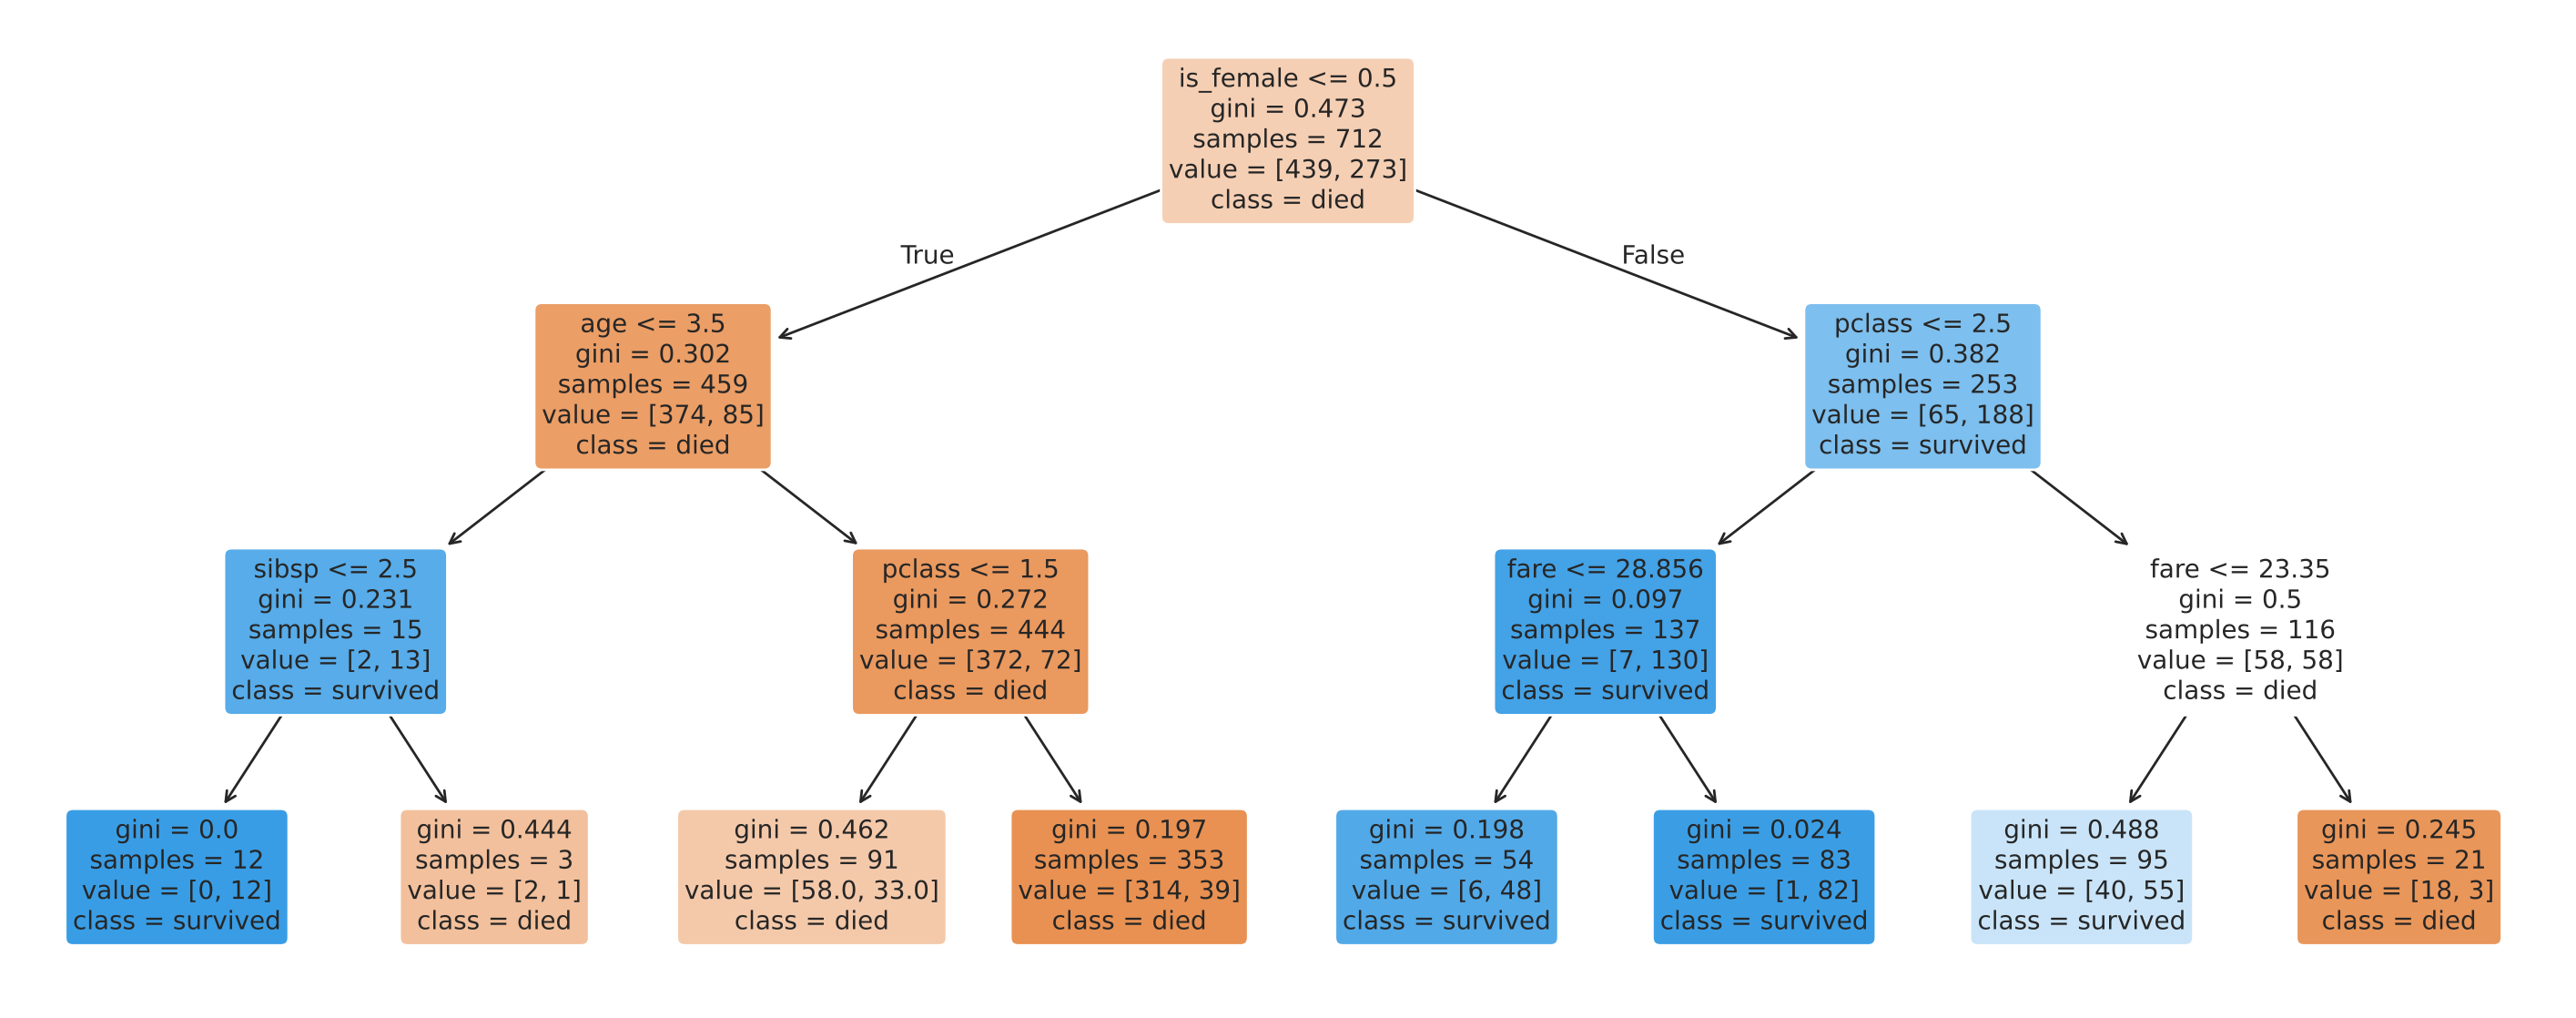

In [5]:
titanic = pd.read_csv(DATA_URL + "titanic.csv")
features = ["pclass", "sex", "age", "sibsp", "parch", "fare"]
Xt = titanic[features].assign(sex=(titanic["sex"] == "female").astype(int),
                              age=titanic["age"].fillna(titanic["age"].median()))
Xt_train, Xt_test, yt_train, yt_test = train_test_split(Xt, titanic["survived"], test_size=0.2,
                                                        stratify=titanic["survived"], random_state=42)
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(Xt_train, yt_train)
print(f"Test accuracy: {tree.score(Xt_test, yt_test):.3f}")

plt.figure(figsize=(18, 7))
plot_tree(tree, feature_names=["pclass", "is_female", "age", "sibsp", "parch", "fare"],
          class_names=["died", "survived"], filled=True, rounded=True, fontsize=10)
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

(برای سادگی، `sex` را به ستون صفر و یک `is_female` تبدیل کردیم و سن گمشده را با میانه پر کردیم.)

قوانین درخت دقیقاً همان یافته‌های EDA جلسهٔ ۲ هستند:
- **اولین سؤال جنسیت است**؛ قوی‌ترین عامل نجات.
- برای زنان، سؤال بعدی **درجهٔ بلیت** است: زنان درجهٔ یک و دو تقریباً همه نجات یافته‌اند.
- برای مردان، **سن** مهم است: پسربچه‌ها شانس بسیار بیشتری از مردان بالغ داشته‌اند («اول زنان و کودکان»).

درخت‌های کم‌عمق ابزار عالی برای **توضیح** الگوهای داده به افراد غیرفنی‌اند.

</div>